In [ ]:
import sys
from pathlib import Path
_ROOT = Path.cwd().parent.resolve()
if str(_ROOT) not in sys.path:
    sys.path.insert(0, str(_ROOT))

from    pathlib         import  Path
from    tqdm.notebook   import  tqdm, trange

import  torch
from    torch.utils.data    import  TensorDataset, DataLoader
import  matplotlib.pyplot   as  plt

from    core.utils    import  velocity_grid, relative_error
from    core.numerical.math   import  area_of_unit_sphere
from    core.numerical.solver     import  LAMBDA, one_step_RK4_classic
from    core.numerical.distribution   import  maxwellian_homogeneous, compute_moments_homogeneous
from    core.neural.collision_op  import  PRFNO


from    loader  import  load_dataset


DEVICE = torch.device('cuda:1')
base_path = _ROOT
assert base_path.exists()

In [2]:
__n_parts: dict[tuple[int, int], int] = {
    (3,  32): 10,
}

DIMENSION   = 3
N_LAYERS    = 4
MAX_FREQ    = 8
SEED        = 0
MODEL_TYPE  = "prfno"

DELTA_T     = 0.1
MAX_T       = 5.0
RES_T       = int(1.05+(MAX_T/DELTA_T))
LTE_T       = 20.0
RES_T_LTE   = int(1.05+(LTE_T/DELTA_T))
RESOLUTION  = 2**5
MAX_V       = 3.0/LAMBDA

PART_INIT   = 1
PART_LAST   = __n_parts[(DIMENSION, RESOLUTION)]
COL_COEFF   = 1/(2*torch.pi)
EXP_SPEED   = torch.arange(21)*0.05

BATCH_SIZE  = 2**7

path = base_path/"pretrained"/f"{MODEL_TYPE.upper()}_{DIMENSION}D"
model_and_history = torch.load(path/"model_and_history.pth", weights_only=False, map_location='cpu')
INVERSE_COEFF = float(model_and_history['inverse_coeff'])
print(model_and_history.keys())

dict_keys(['args', 'state_dict', 'train_history', 'inverse_coeff'])


In [3]:
# Load data
traj, param = load_dataset(DIMENSION, RESOLUTION, EXP_SPEED, PART_LAST, coeff=COL_COEFF)
print(traj.shape)
print(param.shape)

# Generate dataloader
test_dataloader = DataLoader(TensorDataset(traj[:, 0], param), batch_size=BATCH_SIZE, shuffle=False)

  0%|          | 0/210 [00:00<?, ?it/s]

Loaded 840 trajectories from /media/junseung/47a90e46-3a9d-467c-bbee-066752b68532/GWANGJAE/parameterized_neural_collision/datasets/test/Boltzmann_3D__coeff1.59e-01__res_t051_v032.
torch.Size([840, 51, 32, 32, 32, 1])
torch.Size([840, 1])


In [4]:
prfno = PRFNO(**model_and_history['args']).to(DEVICE)
prfno.load_state_dict(model_and_history['state_dict'])
prfno.eval()
v_grid = velocity_grid(DIMENSION, RESOLUTION, MAX_V, device=DEVICE)

In [5]:
from    tqdm.notebook   import  tqdm
pred_list = []
with torch.inference_mode():
    for f_init, params in tqdm(test_dataloader):
        f_pred   = f_init.to(DEVICE)
        params   = params.to(DEVICE)
        pred_list_batch = [f_pred.clone().cpu()]
        fwd = lambda t, f: (COL_COEFF/INVERSE_COEFF)*prfno.forward(f, v_grid, params)
        for _ in trange(RES_T-1):
            f_pred = one_step_RK4_classic(0.0, f_pred, DELTA_T, fwd)
            pred_list_batch.append(f_pred.clone().cpu())
        pred_list_batch = torch.stack(pred_list_batch, dim=1)
        pred_list.append(pred_list_batch)
pred_list = torch.cat(pred_list, dim=0)

  0%|          | 0/7 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

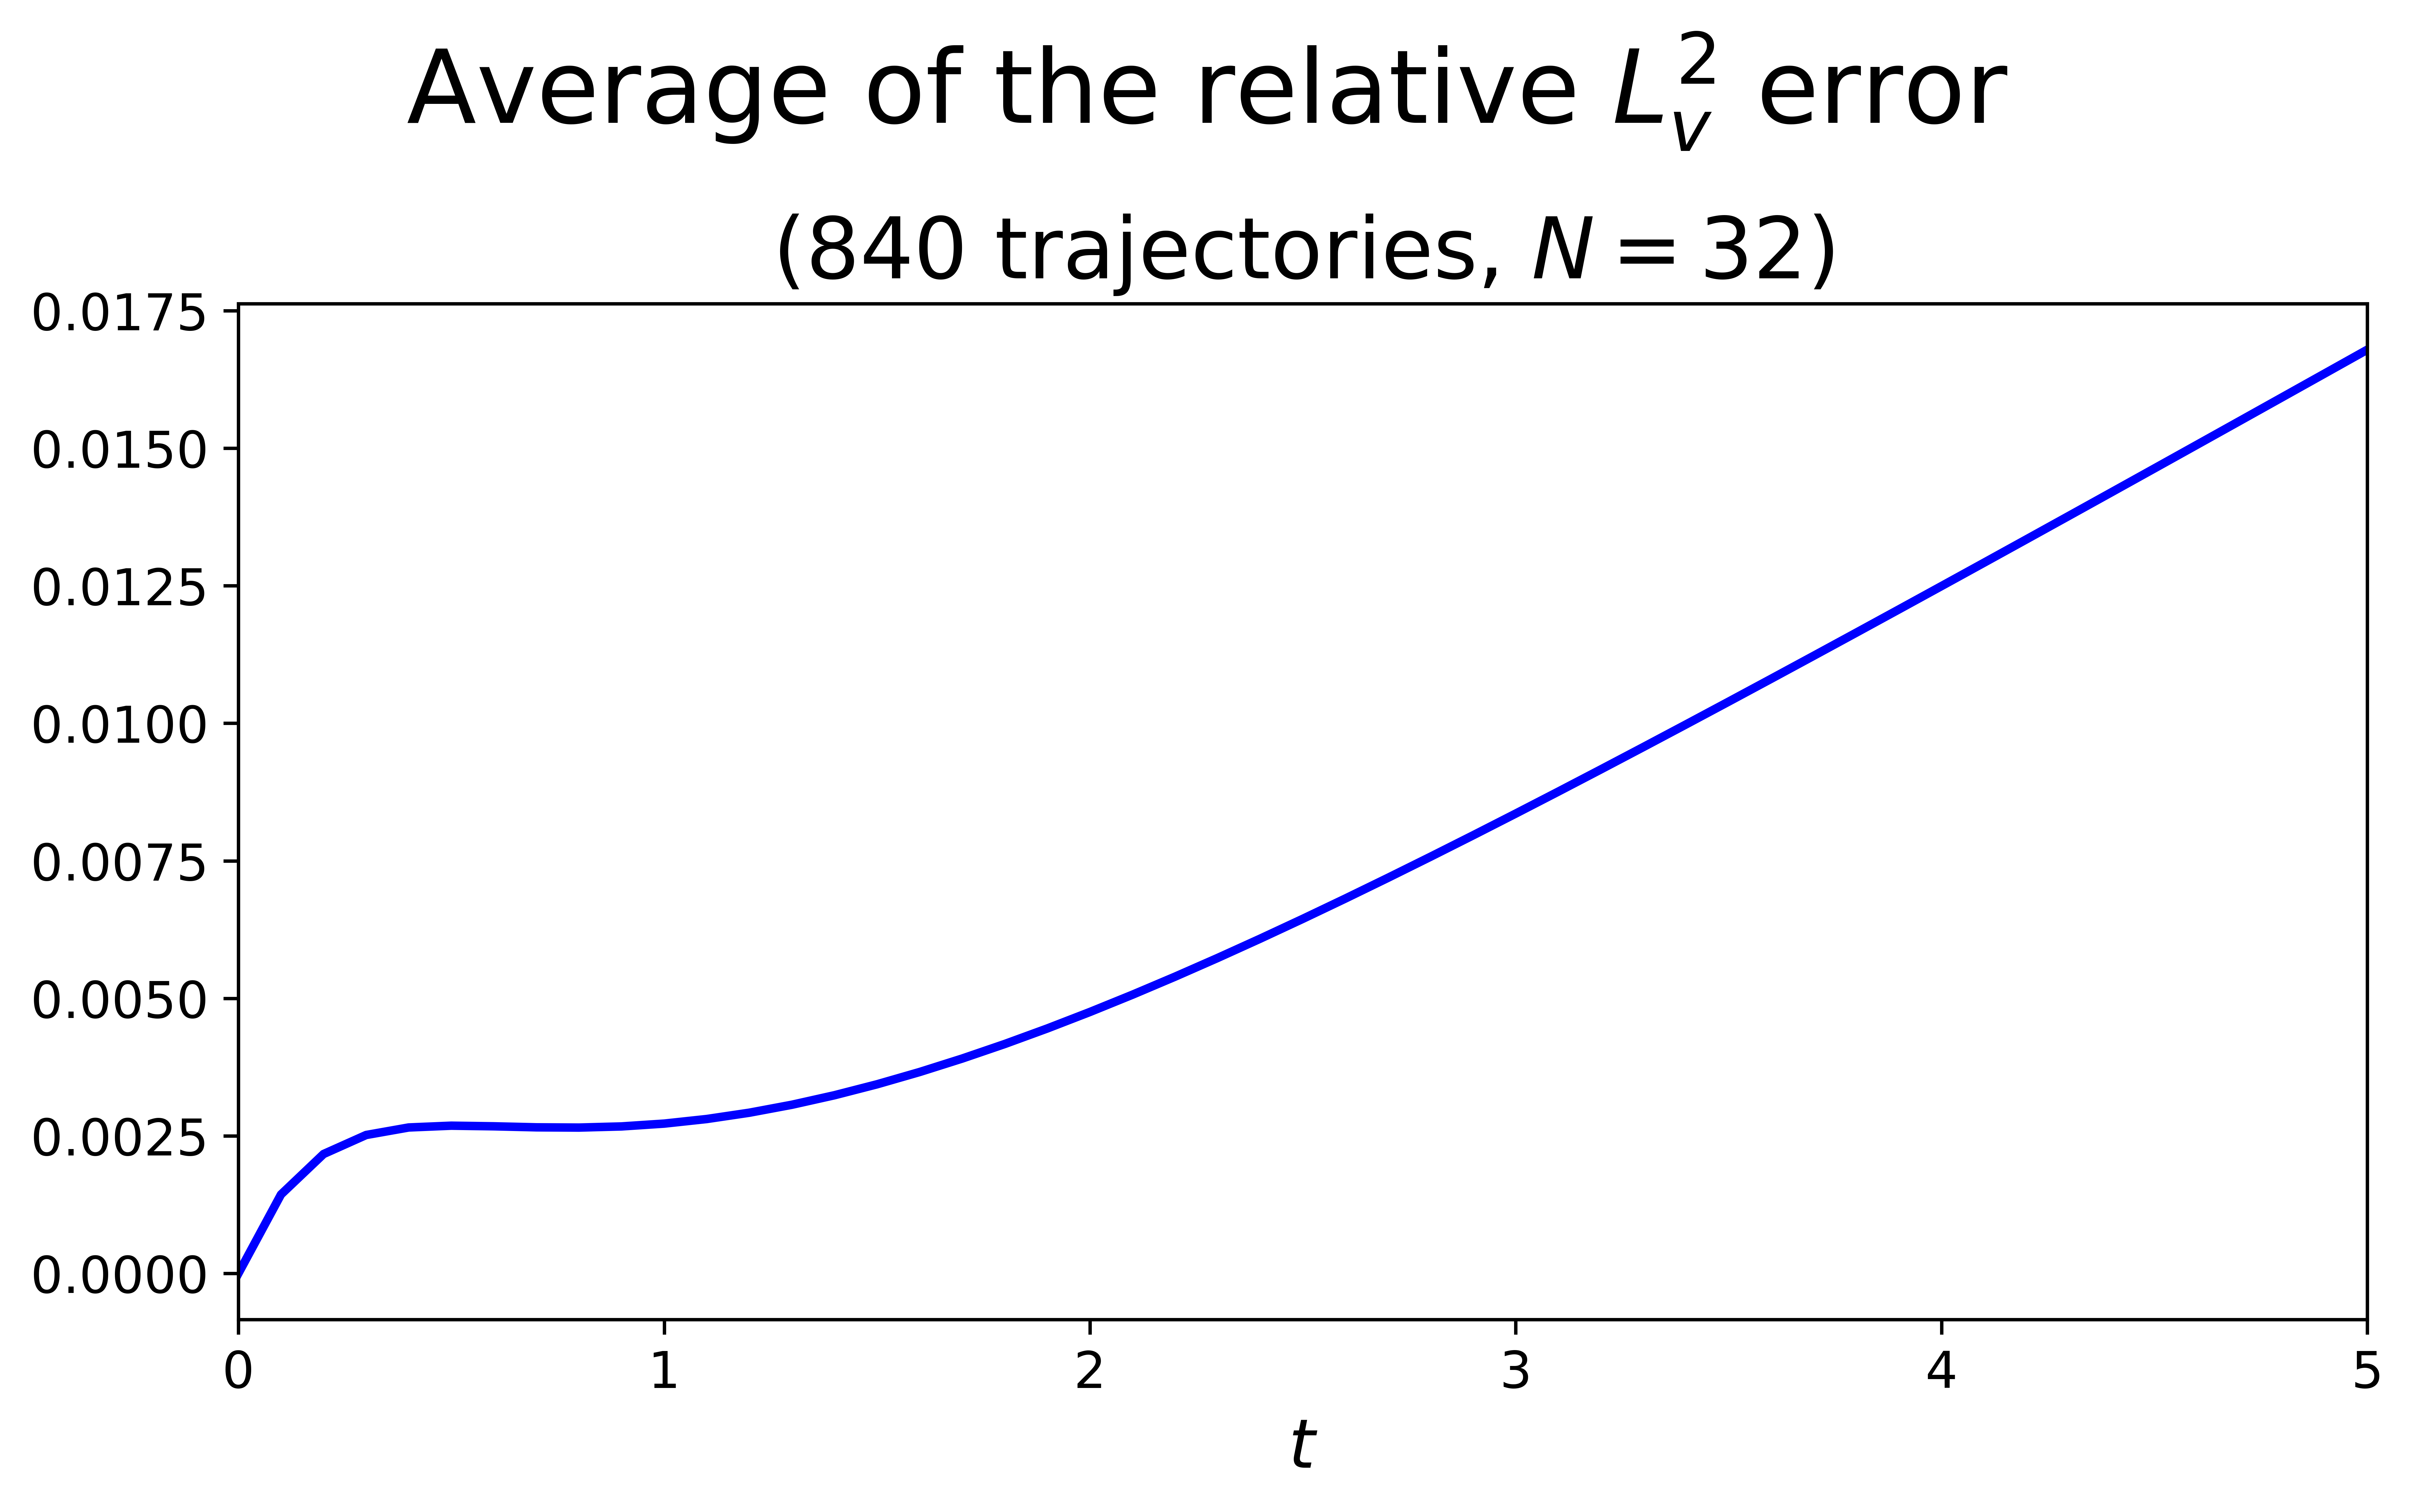

In [6]:
error = relative_error(pred_list, traj, p=2, dim=tuple(range(2, 2+DIMENSION+1)))

arr_t = torch.arange(RES_T)*DELTA_T
error_mean = error.mean(dim=0)
error_std  = error.std(dim=0)

plt.figure(figsize=(8, 5), dpi=1000)
plt.suptitle(f"Average of the relative $L^2_{{v}}$ error", fontsize=24)
plt.title(f"({traj.size(0)} trajectories, $N={RESOLUTION}$)", fontsize=20)
plt.plot(arr_t, error_mean.cpu(), c='blue', linewidth=2)

plt.xlabel("$t$", fontsize=16)
plt.xlim(arr_t.min(), arr_t.max())
plt.tick_params(labelsize=12)

plt.tight_layout()
plt.show()

End of file